saved Fig1_construction  |  108 pairs, 216 questions, 120 decoys, 108 probes


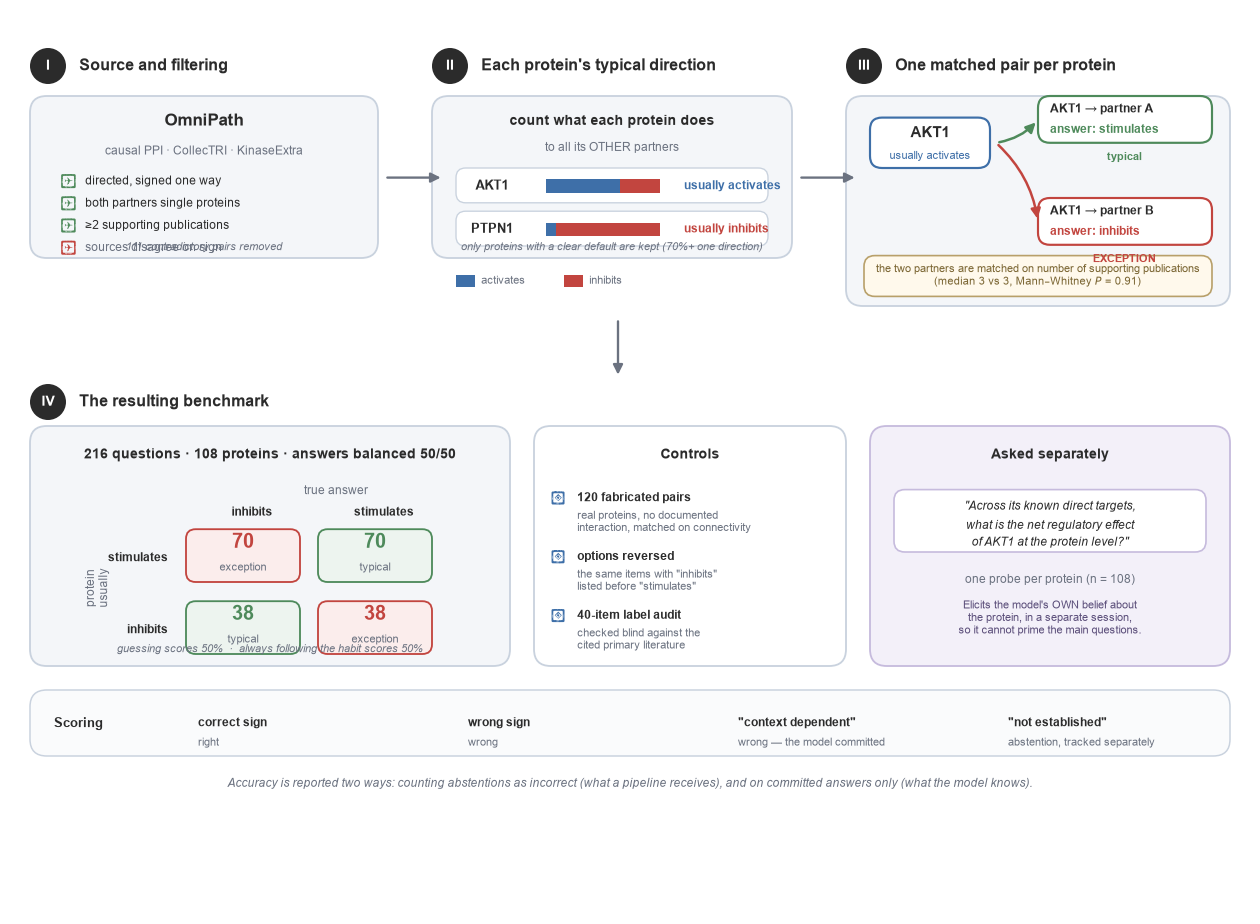

In [2]:
# ============================================================================
# 06a — FIGURE 1: BENCHMARK CONSTRUCTION
# ----------------------------------------------------------------------------
# Four-stage schematic in the style used by benchmark-construction papers:
#   I   source and filtering
#   II  identify each protein's typical direction
#   III build one matched pair per protein
#   IV  the final design and the two controls
# All counts are read from the built benchmark, not hard-coded.
# ============================================================================
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle, Circle

ROOT = Path.cwd().parent
PROC = ROOT/"data"/"processed"; FIG = ROOT/"figures"/"final_set"
FIG.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
 "figure.dpi":120,"savefig.dpi":400,"savefig.bbox":"tight","savefig.pad_inches":0.15,
 "pdf.fonttype":42,"ps.fonttype":42,"font.family":"sans-serif",
 "font.sans-serif":["Arial","Helvetica","DejaVu Sans"],"font.size":8.5})

INK,MUTE   = "#2b2b2b","#6b7280"
GREEN,RED  = "#4E8A5B","#C2453F"
BLUE,SAND  = "#3E6FA8","#B8A06A"
PANEL,EDGE = "#F4F6F9","#C9D2DE"

B = pd.read_json(PROC/"sighabit_v2.jsonl", lines=True)
FULLB = pd.read_json(PROC/"sighabit_v2_full.jsonl", lines=True)
USUALB = pd.read_json(PROC/"sighabit_v2_usually.jsonl", lines=True)
META = json.loads((PROC/"sighabit_v2.meta.json").read_text())
n_pair = B.pair_id.nunique(); n_dec = int(FULLB.is_decoy.sum())
ct = pd.crosstab(B.protein_usually, B.answer)

fig = plt.figure(figsize=(10.2, 7.4))
ax = fig.add_axes([0,0,1,1]); ax.set_xlim(0,102); ax.set_ylim(0,74); ax.axis("off")

def box(x,y,w,h,fc="white",ec=EDGE,lw=1.1,r=1.4,z=2,ls="-"):
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle=f"round,pad=0,rounding_size={r}",
        fc=fc,ec=ec,lw=lw,zorder=z,linestyle=ls))
def txt(x,y,s,**k):
    k.setdefault("ha","center"); k.setdefault("va","center")
    k.setdefault("fontsize",8); k.setdefault("color",INK); k.setdefault("zorder",4)
    ax.text(x,y,s,**k)
def arrow(x1,y1,x2,y2,c=MUTE,lw=1.4,rad=0,st="-|>",ms=12):
    ax.add_patch(FancyArrowPatch((x1,y1),(x2,y2),arrowstyle=st,mutation_scale=ms,
        lw=lw,color=c,zorder=3,connectionstyle=f"arc3,rad={rad}"))
def stage(x,y,n,title):
    ax.add_patch(Circle((x,y),1.5,fc=INK,ec="none",zorder=5))
    txt(x,y,n,color="white",fontsize=8.5,fontweight="bold",zorder=6)
    txt(x+2.6,y,title,ha="left",fontsize=9.5,fontweight="bold")

# ---------------- I. SOURCE AND FILTERING --------------------------------
stage(2.5,70,"I","Source and filtering")
box(1,54,29,13.5,fc=PANEL)
txt(15.5,65.4,"OmniPath",fontsize=10,fontweight="bold")
txt(15.5,62.9,"causal PPI · CollecTRI · KinaseExtra",fontsize=7.2,color=MUTE)
for i,(s,keep) in enumerate([("directed, signed one way",True),
                             ("both partners single proteins",True),
                             ("≥2 supporting publications",True),
                             ("sources disagree on sign",False)]):
    yy = 60.4-i*1.85
    txt(4.2,yy,"✓" if keep else "✗",color=GREEN if keep else RED,
        fontsize=9,fontweight="bold")
    txt(5.6,yy,s,ha="left",fontsize=7.2,color=INK if keep else MUTE)
txt(15.5,54.9,f"{META.get('n_sign_conflicted_removed','111')} contradictory pairs removed",
    fontsize=6.8,color=MUTE,style="italic")

arrow(30.5,60.7,35.5,60.7)

# ---------------- II. TYPICAL DIRECTION ----------------------------------
stage(36,70,"II","Each protein's typical direction")
box(34.5,54,30,13.5,fc=PANEL)
txt(49.5,65.4,"count what each protein does",fontsize=8.6,fontweight="bold")
txt(49.5,63.2,"to all its OTHER partners",fontsize=7.2,color=MUTE)
# two example proteins
for i,(g,act,inh,us,c) in enumerate([("AKT1",72,39,"activates",BLUE),
                                     ("PTPN1",2,20,"inhibits",RED)]):
    yy = 60.0-i*3.6
    box(36.5,yy-1.4,26,2.9,fc="white",ec=EDGE,lw=.8,r=.8)
    txt(39.5,yy,g,fontsize=8,fontweight="bold")
    tot=act+inh; bw=9.5
    ax.add_patch(Rectangle((44,yy-.55),bw*act/tot,1.1,fc=BLUE,ec="none",zorder=4))
    ax.add_patch(Rectangle((44+bw*act/tot,yy-.55),bw*inh/tot,1.1,fc=RED,ec="none",zorder=4))
    txt(55.5,yy,f"usually {us}",ha="left",fontsize=7.2,color=c,fontweight="bold")
txt(49.5,54.9,"only proteins with a clear default are kept "
    f"({int(META.get('usual_threshold_stim',0.70)*100)}%+ one direction)",
    fontsize=6.8,color=MUTE,style="italic")
ax.add_patch(Rectangle((36.5,51.6),1.6,1.0,fc=BLUE,ec="none"))
txt(38.6,52.1,"activates",ha="left",fontsize=6.8,color=MUTE)
ax.add_patch(Rectangle((45.5,51.6),1.6,1.0,fc=RED,ec="none"))
txt(47.6,52.1,"inhibits",ha="left",fontsize=6.8,color=MUTE)

arrow(65,60.7,70,60.7)

# ---------------- III. MATCHED PAIR --------------------------------------
stage(70.5,70,"III","One matched pair per protein")
box(69,50,32,17.5,fc=PANEL)
box(71,61.5,10,4.2,fc="white",ec=BLUE,lw=1.3,r=1.0)
txt(76,64.4,"AKT1",fontsize=9,fontweight="bold")
txt(76,62.5,"usually activates",fontsize=6.8,color=BLUE)
for yy,tgt,tru,lb,c in [(64.0,"partner A","stimulates","typical",GREEN),
                        (55.5,"partner B","inhibits","EXCEPTION",RED)]:
    arrow(81.5,63.6,85.0,yy+1.5,c=c,rad=0.18 if yy>60 else -0.18,lw=1.5)
    box(85,yy-0.4,14.5,3.9,fc="white",ec=c,lw=1.3,r=1.0)
    txt(86,yy+2.4,f"AKT1 → {tgt}",ha="left",fontsize=7.4,fontweight="bold")
    txt(86,yy+0.7,f"answer: {tru}",ha="left",fontsize=7,color=c,fontweight="bold")
    txt(92.2,yy-1.6,lb,fontsize=6.6,color=c,fontweight="bold")
box(70.5,50.8,29,3.4,fc="#FFF9EC",ec=SAND,lw=1.0,r=.9)
txt(85,52.5,"the two partners are matched on number of supporting publications\n"
    "(median 3 vs 3, Mann–Whitney $P$ = 0.91)",fontsize=6.9,color="#7A6532")

arrow(50,49,50,44,rad=0)

# ---------------- IV. DESIGN AND CONTROLS --------------------------------
stage(2.5,42,"IV","The resulting benchmark")

# 2x2 design grid
box(1,20,40,20,fc=PANEL)
txt(21,37.6,"216 questions · 108 proteins · answers balanced 50/50",
    fontsize=8.4,fontweight="bold")
txt(26.5,34.6,"true answer",fontsize=7,color=MUTE)
for j,c in enumerate(["inhibits","stimulates"]):
    txt(19.5+j*11,32.8,c,fontsize=7.4,fontweight="bold")
txt(6.6,26.5,"protein\nusually",fontsize=7,color=MUTE,rotation=90)
for i,r in enumerate(["stimulates","inhibits"]):
    txt(12.5,29.0-i*6.0,r,ha="right",fontsize=7.4,fontweight="bold")
    for j,c in enumerate(["inhibits","stimulates"]):
        n=int(ct.loc[r,c]); hard=(r!=c)
        box(14+j*11,27.0-i*6.0,9.5,4.4,fc="#FBEDEC" if hard else "#EDF4EF",
            ec=RED if hard else GREEN,lw=1.1,r=.8)
        txt(18.75+j*11,30.3-i*6.0,str(n),fontsize=12,fontweight="bold",
            color=RED if hard else GREEN)
        txt(18.75+j*11,28.2-i*6.0,"exception" if hard else "typical",
            fontsize=6.8,color=MUTE)
txt(21,21.4,"guessing scores 50%  ·  always following the habit scores 50%",
    fontsize=6.9,color=MUTE,style="italic")

# controls column
box(43,20,26,20,fc="white",ec=EDGE)
txt(56,37.6,"Controls",fontsize=8.6,fontweight="bold")
for i,(t,d) in enumerate([
    (f"{n_dec} fabricated pairs",
     "real proteins, no documented\ninteraction, matched on connectivity"),
    ("options reversed",
     'the same items with "inhibits"\nlisted before "stimulates"'),
    ("40-item label audit",
     "checked blind against the\ncited primary literature")]):
    yy = 34.0-i*4.9
    txt(45,yy,"▸",fontsize=8,color=BLUE)
    txt(46.6,yy,t,ha="left",fontsize=7.4,fontweight="bold")
    txt(46.6,yy-2.0,d,ha="left",va="center",fontsize=6.7,color=MUTE)

# separate probe
box(71,20,30,20,fc="#F3F0F9",ec="#C6BBDD")
txt(86,37.6,"Asked separately",fontsize=8.6,fontweight="bold")
box(73,29.5,26,5.2,fc="white",ec="#C6BBDD",lw=1.0,r=.9)
txt(86,33.3,'"Across its known direct targets,',fontsize=7,style="italic")
txt(86,31.7,'what is the net regulatory effect',fontsize=7,style="italic")
txt(86,30.3,'of AKT1 at the protein level?"',fontsize=7,style="italic")
txt(86,27.2,f"one probe per protein (n = {len(USUALB)})",fontsize=7,color=MUTE)
txt(86,24.0,"Elicits the model's OWN belief about\nthe protein, in a separate session,\n"
    "so it cannot prime the main questions.",fontsize=6.9,color="#5B4E7A")

# footer
box(1,12.5,100,5.5,fc="#FAFBFC",ec=EDGE,lw=.9)
txt(3,15.2,"Scoring",ha="left",fontsize=8,fontweight="bold")
for i,(k,v,c) in enumerate([("correct sign","right",GREEN),
                            ("wrong sign","wrong",RED),
                            ('"context dependent"',"wrong — the model committed",RED),
                            ('"not established"',"abstention, tracked separately",SAND)]):
    xx = 13+i*22.5
    ax.add_patch(Rectangle((xx,14.6),1.3,1.3,fc=c,ec="none"))
    txt(xx+2,15.25,k,ha="left",fontsize=7.1,fontweight="bold")
    txt(xx+2,13.6,v,ha="left",fontsize=6.6,color=MUTE)

txt(51,10.2,"Accuracy is reported two ways: counting abstentions as incorrect "
    "(what a pipeline receives), and on committed answers only (what the model knows).",
    fontsize=7.2,color=MUTE,style="italic")

for e in ("png","pdf","svg"): fig.savefig(FIG/f"Fig1_construction.{e}")
print(f"saved Fig1_construction  |  {n_pair} pairs, {len(B)} questions, "
      f"{n_dec} decoys, {len(USUALB)} probes")
plt.show()

  saved Fig2_main_result


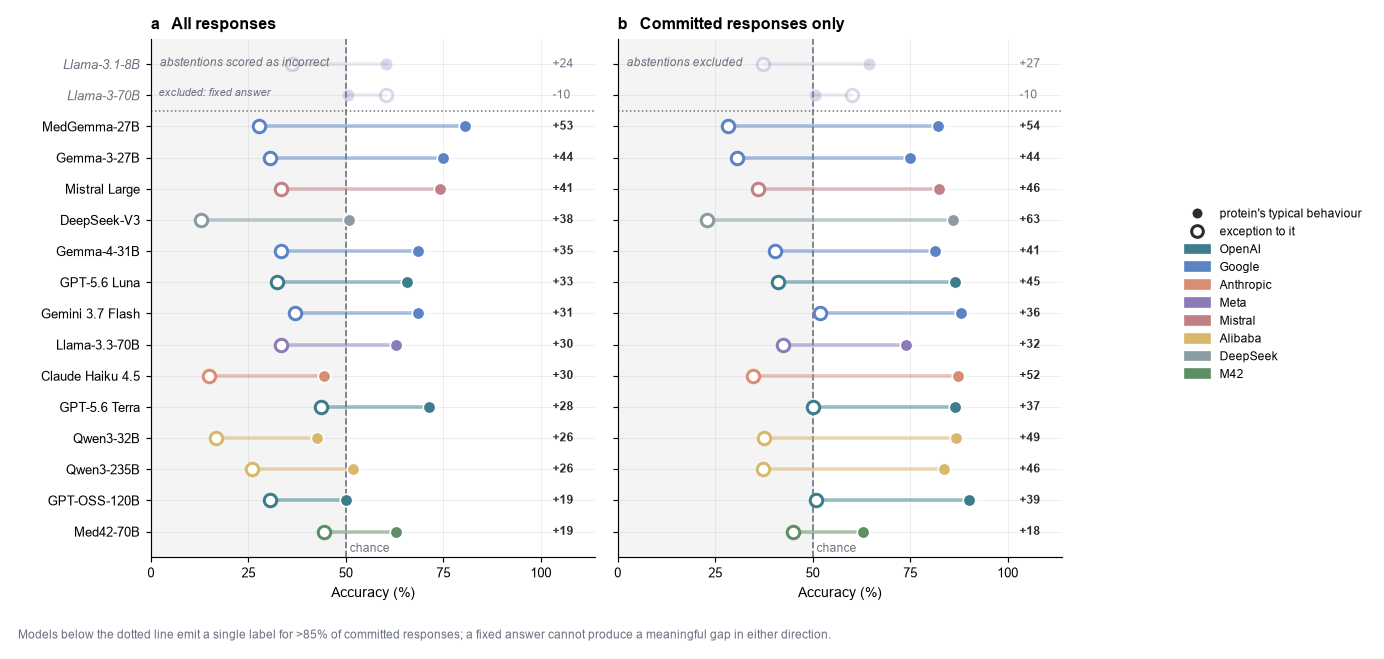

Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.


  saved Fig3_controls


Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u226b' [U+226b], substituting with a dummy symbol.


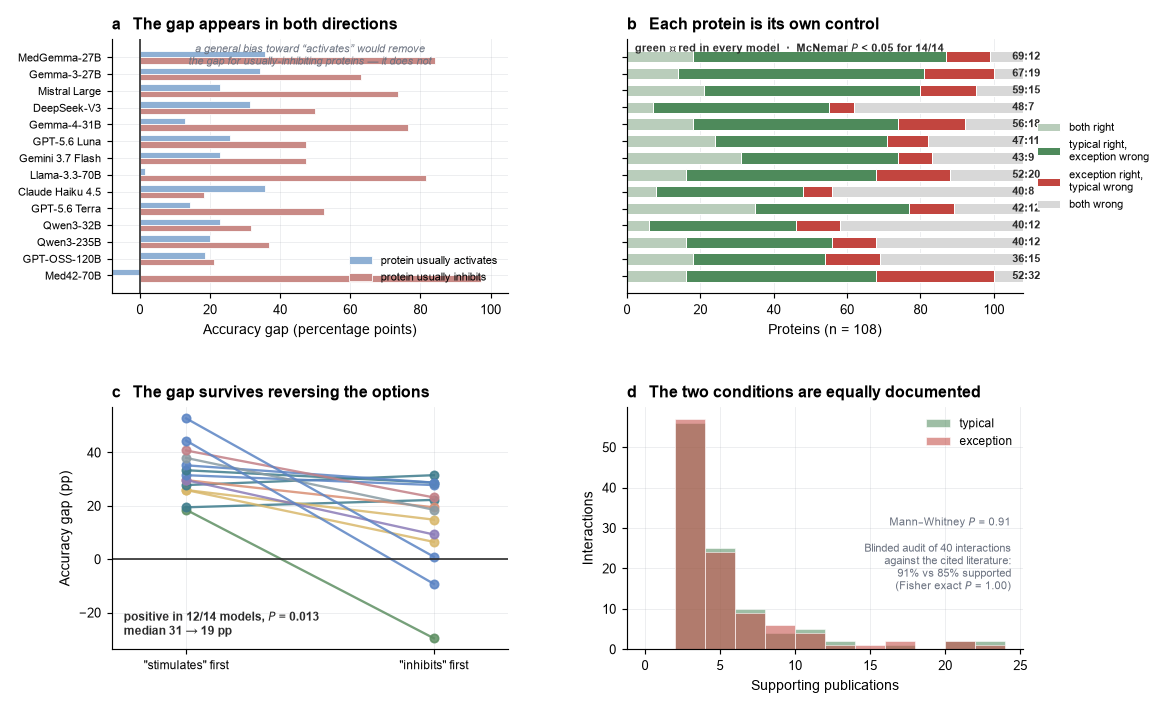

  saved Fig4_mechanism


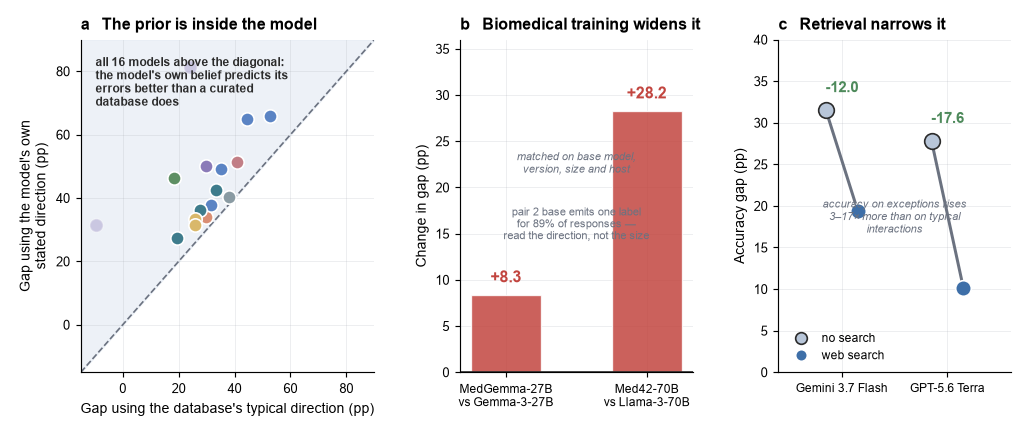


all figures in c:\Users\tauhe\Desktop\SigHabitBench\figures\final_set


In [3]:
# ============================================================================
# 06b — FIGURES 2 AND 3
# ============================================================================
import warnings; warnings.filterwarnings("ignore")
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import binomtest

RES = ROOT/"results"
mpl.rcParams.update({
 "axes.titlesize":9.5,"axes.titleweight":"bold","axes.labelsize":8.5,
 "xtick.labelsize":7.8,"ytick.labelsize":7.8,"legend.fontsize":7.4,
 "axes.linewidth":0.7,"axes.spines.top":False,"axes.spines.right":False,
 "axes.grid":True,"grid.alpha":0.20,"grid.linewidth":0.5,"grid.color":"#9aa0a6",
 "legend.frameon":False,"axes.axisbelow":True})

DEV={"gpt-5.6-terra":"OpenAI","gpt-5.6-luna":"OpenAI","gpt-oss-120b":"OpenAI",
 "gemini-3.7-flash":"Google","gemma-3-27b":"Google","gemma-4-31b":"Google",
 "medgemma-27b":"Google","claude-haiku-4.5":"Anthropic","llama-3-70b":"Meta",
 "llama-3.1-8b":"Meta","llama-3.3-70b":"Meta","mistral-large":"Mistral",
 "qwen3-32b":"Alibaba","qwen3-235b":"Alibaba","deepseek-v3":"DeepSeek",
 "med42-70b":"M42"}
DEVCOL={"OpenAI":"#3E7C8C","Google":"#5B84C4","Anthropic":"#D98E73","Meta":"#8B7BB8",
 "Mistral":"#C27F86","Alibaba":"#D9B86B","DeepSeek":"#8A9BA3","M42":"#5E8F63"}
def col(m): return DEVCOL.get(DEV.get(m,""),"#9aa0a6")
LBL={"gemini-3.7-flash":"Gemini 3.7 Flash","gpt-5.6-terra":"GPT-5.6 Terra",
 "gpt-5.6-luna":"GPT-5.6 Luna","gpt-oss-120b":"GPT-OSS-120B","gemma-3-27b":"Gemma-3-27B",
 "gemma-4-31b":"Gemma-4-31B","medgemma-27b":"MedGemma-27B",
 "claude-haiku-4.5":"Claude Haiku 4.5","llama-3-70b":"Llama-3-70B",
 "llama-3.1-8b":"Llama-3.1-8B","llama-3.3-70b":"Llama-3.3-70B",
 "mistral-large":"Mistral Large","qwen3-32b":"Qwen3-32B","qwen3-235b":"Qwen3-235B",
 "deepseek-v3":"DeepSeek-V3","med42-70b":"Med42-70B"}
def lab(m): return LBL.get(m,m)
def save(f,n):
    for e in ("png","pdf","svg"): f.savefig(FIG/f"{n}.{e}")
    print(f"  saved {n}")

A=pd.concat([pd.read_json(p,lines=True) for p in sorted(RES.glob("*.jsonl"))],
            ignore_index=True)
A=A[A.http==200].copy()
A["abstained"]=A.pred=="not_established"
A["committed"]=A.pred.notna()&~A.abstained
A["correct"]=A.pred.notna()&(A.pred==A.truth)
MAIN=A[(A.arm=="main")&(~A.is_decoy)]; DEC=A[(A.arm=="main")&A.is_decoy]
SW=A[A.arm=="swap"]; WEB=A[A.arm=="web"]; U=A[A.arm=="usually"]
MODELS_=sorted(MAIN.model.unique())
def acc(d,c): return d[d.condition==c].correct.mean()
def gap(d,m=None):
    if m is not None: d=d[d.model==m]
    return (acc(d,"habit_agrees")-acc(d,"habit_misleads"))*100
ONESIDED=[]
for m in MODELS_:
    c=MAIN[(MAIN.model==m)&MAIN.committed]; v=c.pred.value_counts(normalize=True)
    v=v[v.index.isin(["stimulates","inhibits"])]
    if len(v) and v.max()>0.85: ONESIDED.append(m)
INFORM=[m for m in MODELS_ if m not in ONESIDED]

# ======================= FIGURE 2 — MAIN RESULT ==========================
# excluded models are placed at the BOTTOM, not mixed into the ranking
order = sorted(INFORM,key=lambda m:gap(MAIN,m)) + sorted(ONESIDED,key=lambda m:gap(MAIN,m))
fig,ax=plt.subplots(1,2,figsize=(9.8,5.6),sharey=True,gridspec_kw={"wspace":0.05})
for k,(only_c,ttl,sub) in enumerate([
    (False,"a   All responses","abstentions scored as incorrect"),
    (True ,"b   Committed responses only","abstentions excluded")]):
    ax[k].axvspan(0,50,color="#f4f4f4",zorder=0)
    ax[k].axvline(50,ls="--",lw=1.0,color=MUTE,zorder=1)
    ax[k].axhline(len(INFORM)-0.5,lw=.9,color=MUTE,ls=":",zorder=1)
    for i,m in enumerate(order):
        d=MAIN[MAIN.model==m]
        if only_c: d=d[d.committed]
        a,b_=acc(d,"habit_agrees")*100,acc(d,"habit_misleads")*100
        c=col(m); al=.30 if m in ONESIDED else 1.0
        ax[k].plot([b_,a],[i,i],lw=2.2,color=c,alpha=al*.5,solid_capstyle="round",zorder=2)
        ax[k].scatter(b_,i,s=56,marker="o",color="white",edgecolor=c,lw=1.8,zorder=3,alpha=al)
        ax[k].scatter(a,i,s=56,marker="o",color=c,edgecolor="white",lw=1.0,zorder=3,alpha=al)
        ax[k].text(103,i,f"{a-b_:+.0f}",va="center",fontsize=7.2,
                   color=MUTE if m in ONESIDED else INK,
                   fontweight="normal" if m in ONESIDED else "bold")
    ax[k].set_xlim(0,114); ax[k].set_ylim(-0.8,len(order)-0.2)
    ax[k].set_xticks([0,25,50,75,100]); ax[k].set_xlabel("Accuracy (%)")
    ax[k].set_title(ttl,loc="left")
    ax[k].text(.02,.965,sub,transform=ax[k].transAxes,fontsize=7.3,color=MUTE,
               style="italic",va="top")
    ax[k].text(51,-0.65,"chance",fontsize=7,color=MUTE)
ax[0].set_yticks(np.arange(len(order)))
ax[0].set_yticklabels([lab(m) for m in order])
for t,m in zip(ax[0].get_yticklabels(),order):
    if m in ONESIDED: t.set_color(MUTE); t.set_fontstyle("italic")
ax[0].text(2,len(INFORM)-0.1,"excluded: fixed answer",fontsize=6.8,color=MUTE,
           style="italic",va="bottom")
h=[Line2D([],[],marker="o",ls="",mfc=INK,mec="white",ms=7,label="protein's typical behaviour"),
   Line2D([],[],marker="o",ls="",mfc="white",mec=INK,mew=1.8,ms=7,label="exception to it")]
h+=[Patch(color=DEVCOL[d],label=d) for d in
    ["OpenAI","Google","Anthropic","Meta","Mistral","Alibaba","DeepSeek","M42"]]
fig.legend(handles=h,loc="center left",bbox_to_anchor=(0.995,0.5))
fig.text(0.012,-0.012,"Models below the dotted line emit a single label for >85% of "
   "committed responses; a fixed answer cannot produce a meaningful gap in either "
   "direction.",fontsize=7,color=MUTE)
save(fig,"Fig2_main_result"); plt.show()

# ======================= FIGURE 3 — CONTROLS =============================
fig=plt.figure(figsize=(9.8,6.6))
gs=fig.add_gridspec(2,2,hspace=0.46,wspace=0.30,height_ratios=[1.05,1.0])

# (a) both habit directions
a0=fig.add_subplot(gs[0,0])
o2=sorted(INFORM,key=lambda m:gap(MAIN,m)); w=.38
for i,m in enumerate(o2):
    for j,(u_,cl) in enumerate([("stimulates","#8FB0D4"),("inhibits","#C98A86")]):
        d=MAIN[(MAIN.model==m)&(MAIN.protein_usually==u_)]
        a0.barh(i+(w/2 if j==0 else -w/2),gap(d),height=w,color=cl,
                edgecolor="white",lw=.5,
                label=("protein usually activates" if j==0 else "protein usually inhibits")
                      if i==0 else None)
a0.axvline(0,lw=1.0,color=INK)
a0.set_yticks(np.arange(len(o2))); a0.set_yticklabels([lab(m) for m in o2],fontsize=6.9)
a0.set_xlim(-8,105); a0.set_xlabel("Accuracy gap (percentage points)")
a0.set_title("a   The gap appears in both directions",loc="left")
a0.legend(loc="lower right",fontsize=6.9)
a0.text(.50,.985,"a general bias toward “activates” would remove\n"
        "the gap for usually-inhibiting proteins — it does not",
        transform=a0.transAxes,ha="center",va="top",fontsize=6.8,color=MUTE,style="italic")

# (b) paired outcomes as stacked bars — no wasted space
a1=fig.add_subplot(gs[0,1])
rows=[]
for m in o2:
    p=MAIN[MAIN.model==m].pivot_table(index="source",columns="condition",
        values="correct",aggfunc="first").dropna()
    rows.append(dict(m=m,
        ao=int((p.habit_agrees&~p.habit_misleads).sum()),
        bo=int((~p.habit_agrees&p.habit_misleads).sum()),
        both=int((p.habit_agrees&p.habit_misleads).sum()),
        none=int((~p.habit_agrees&~p.habit_misleads).sum())))
P=pd.DataFrame(rows)
y=np.arange(len(P)); left=np.zeros(len(P))
for c,cl,l in [("both","#B9CDBB","both right"),
               ("ao","#4E8A5B","typical right,\nexception wrong"),
               ("bo","#C2453F","exception right,\ntypical wrong"),
               ("none","#D8D8D8","both wrong")]:
    a1.barh(y,P[c],left=left,height=.68,color=cl,edgecolor="white",lw=.6,label=l)
    left=left+P[c].values
a1.set_yticks(y); a1.set_yticklabels([]); a1.set_xlim(0,108)
a1.set_xlabel("Proteins (n = 108)")
a1.set_title("b   Each protein is its own control",loc="left")
a1.legend(loc="center left",bbox_to_anchor=(1.01,0.5),fontsize=6.8)
for i,r in P.iterrows():
    a1.text(105,i,f"{r.ao}:{r.bo}",va="center",fontsize=6.8,color=INK,fontweight="bold")
a1.text(.02,.985,"green ≫ red in every model  ·  McNemar $P$ < 0.05 for 14/14",
        transform=a1.transAxes,va="top",fontsize=6.9,color=INK,fontweight="bold")

# (c) option order
a2=fig.add_subplot(gs[1,0])
o3=[m for m in o2 if m in set(SW.model)]
for m in o3:
    gn=gap(MAIN[MAIN.item_id.isin(set(SW[SW.model==m].item_id))],m)
    a2.plot([0,1],[gn,gap(SW,m)],lw=1.4,color=col(m),alpha=.85,marker="o",ms=5)
a2.axhline(0,lw=1.0,color=INK)
a2.set_xlim(-.3,1.3); a2.set_xticks([0,1])
a2.set_xticklabels(['"stimulates" first','"inhibits" first'],fontsize=7.4)
a2.set_ylabel("Accuracy gap (pp)")
a2.set_title("c   The gap survives reversing the options",loc="left")
sw_g=[gap(SW,m) for m in o3]; k=sum(g>0 for g in sw_g)
a2.text(.03,.06,f"positive in {k}/{len(sw_g)} models, $P$ = "
        f"{binomtest(k,len(sw_g),0.5).pvalue:.3f}\n"
        f"median {np.median([gap(MAIN,m) for m in o3]):.0f} → {np.median(sw_g):.0f} pp",
        transform=a2.transAxes,fontsize=7.2,fontweight="bold",color=INK)

# (d) evidence matching + audit
a3=fig.add_subplot(gs[1,1])
b=np.arange(0,26,2)
for c,cl,l in [("habit_agrees",GREEN,"typical"),("habit_misleads",RED,"exception")]:
    a3.hist(B[B.condition==c].n_refs.clip(0,25),bins=b,alpha=.55,color=cl,
            label=l,edgecolor="white",lw=.6)
a3.set_xlabel("Supporting publications"); a3.set_ylabel("Interactions")
a3.set_title("d   The two conditions are equally documented",loc="left")
a3.legend(loc="upper right",fontsize=7.2)
a3.text(.97,.55,"Mann–Whitney $P$ = 0.91\n\n"
        "Blinded audit of 40 interactions\nagainst the cited literature:\n"
        "91% vs 85% supported\n(Fisher exact $P$ = 1.00)",
        transform=a3.transAxes,ha="right",va="top",fontsize=6.9,color=MUTE)
save(fig,"Fig3_controls"); plt.show()

# ======================= FIGURE 4 — MECHANISM ============================
fig=plt.figure(figsize=(10.0,3.6))
gs=fig.add_gridspec(1,3,width_ratios=[1.2,0.95,0.95],wspace=0.34)

a0=fig.add_subplot(gs[0])
for m in MODELS_:
    db=gap(MAIN,m)
    u=U[U.model==m][["source","pred"]].rename(columns={"pred":"own"})
    g=MAIN[MAIN.model==m].merge(u,on="source",how="left")
    g=g[g.own.isin(["stimulates","inhibits"])]
    ow=(g[g.truth==g.own].correct.mean()-g[g.truth!=g.own].correct.mean())*100
    a0.scatter(db,ow,s=64,color=col(m),edgecolor="white",lw=1.0,zorder=3,
               alpha=.35 if m in ONESIDED else 1.0)
lim=(-15,90); a0.plot(lim,lim,ls="--",lw=1.0,color=MUTE,zorder=1)
a0.fill_between(lim,lim,[lim[1]]*2,color="#E7EDF5",alpha=.75,zorder=0)
a0.set_xlim(lim); a0.set_ylim(lim)
a0.set_xlabel("Gap using the database's typical direction (pp)")
a0.set_ylabel("Gap using the model's own\nstated direction (pp)")
a0.set_title("a   The prior is inside the model",loc="left")
a0.text(.05,.95,"all 16 models above the diagonal:\nthe model's own belief predicts its\n"
        "errors better than a curated\ndatabase does",transform=a0.transAxes,
        va="top",fontsize=7.0,color=INK,fontweight="bold")

# (b) biomedical — plot the CHANGE, not two incomparable baselines
a1=fig.add_subplot(gs[1])
PAIRS=[("MedGemma-27B\nvs Gemma-3-27B","gemma-3-27b","medgemma-27b"),
       ("Med42-70B\nvs Llama-3-70B","llama-3-70b","med42-70b")]
d_=[gap(MAIN,f)-gap(MAIN,b_) for _,b_,f in PAIRS if {b_,f}<=set(MODELS_)]
a1.bar(range(len(d_)),d_,width=.5,color=RED,alpha=.85,edgecolor="white",lw=.8)
for i,v in enumerate(d_):
    a1.text(i,v+1.4,f"+{v:.1f}",ha="center",fontsize=9.5,fontweight="bold",color=RED)
a1.axhline(0,lw=1.0,color=INK)
a1.set_xticks(range(len(PAIRS)))
a1.set_xticklabels([p[0] for p in PAIRS],fontsize=7.0)
a1.set_ylabel("Change in gap (pp)"); a1.set_ylim(0,36)
a1.set_title("b   Biomedical training widens it",loc="left")
a1.text(.5,.60,"matched on base model,\nversion, size and host",
        transform=a1.transAxes,ha="center",fontsize=6.9,color=MUTE,style="italic")
a1.text(.5,.40,"pair 2 base emits one label\nfor 89% of responses —\nread the direction, "
        "not the size",transform=a1.transAxes,ha="center",fontsize=6.4,color=MUTE)

# (c) retrieval
a2=fig.add_subplot(gs[2])
for i,m in enumerate(sorted(WEB.model.unique())):
    w=WEB[WEB.model==m]; base=MAIN[(MAIN.model==m)&MAIN.item_id.isin(set(w.item_id))]
    gb,gw=gap(base),gap(w)
    a2.plot([i-.15,i+.15],[gb,gw],lw=1.8,color=MUTE,zorder=1)
    a2.scatter(i-.15,gb,s=88,color="#B8C6D9",edgecolor=INK,lw=1.0,zorder=3)
    a2.scatter(i+.15,gw,s=88,color=BLUE,edgecolor="white",lw=1.0,zorder=3)
    a2.text(i,gb+2.2,f"{gw-gb:+.1f}",ha="center",fontsize=9,fontweight="bold",color=GREEN)
a2.set_xticks(range(WEB.model.nunique()))
a2.set_xticklabels([lab(m) for m in sorted(WEB.model.unique())],fontsize=7.2)
a2.set_ylabel("Accuracy gap (pp)"); a2.set_ylim(0,40); a2.set_xlim(-.6,1.6)
a2.set_title("c   Retrieval narrows it",loc="left")
a2.legend(handles=[Line2D([],[],marker="o",ls="",mfc="#B8C6D9",mec=INK,ms=7,label="no search"),
                   Line2D([],[],marker="o",ls="",mfc=BLUE,mec="white",ms=7,label="web search")],
          loc="lower left",fontsize=7.0)
a2.text(.5,.42,"accuracy on exceptions rises\n3–17× more than on typical\ninteractions",
        transform=a2.transAxes,ha="center",fontsize=6.9,color=MUTE,style="italic")
save(fig,"Fig4_mechanism"); plt.show()
print(f"\nall figures in {FIG}")